# IntelliCluster — Model 3: Resource & Demand Forecasting
## Baseline Algorithm: Multivariate LSTM (Long Short-Term Memory)
This notebook implements Model 3 of the IntelliCluster ML suite:
- **Primary Dataset**: `data/Resource_utilization.csv` (26,305 continuous hourly observations spanning Jan 2022 to Jan 2025)
- **Methodology Baseline**: `data/predicting-service-request-loads.ipynb` (sliding-window sequence lookback)
- **Input Vector**: `cpu_utilization`, `memory_usage`, `storage_usage`, `workload`, `Resource Allocation`
- **Target Variables**: Simultaneous 24-hour joint forecasting of `cpu_utilization`, `memory_usage`, and `workload`.
- **Temporal Integrity**: Chronological train (2022-2023), val (2024-H1), and holdout test (2024-H2) splits with zero random shuffling.
- **Scaling**: `RobustScaler` fitted strictly on training data; telemetry values exceeding 100% are preserved without clipping.


In [1]:
import os
import io
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
print("Environment initialized with RANDOM_STATE =", RANDOM_STATE)

from torch.utils.data import DataLoader, TensorDataset


Environment initialized with RANDOM_STATE = 42


In [2]:
# Ingestion and Chronological Verification
df = pd.read_csv('data/Resource_utilization.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

diffs = (df['timestamp'].diff().iloc[1:].dt.total_seconds()).values
print(f"Total chronological records: {len(df)}")
print(f"Timeline: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Uniform 3600-second interval verification: {np.all(diffs == 3600.0)}")


Total chronological records: 26305
Timeline: 2022-01-01 00:00:00 to 2025-01-01 00:00:00
Uniform 3600-second interval verification: True


In [3]:
# Causal Preprocessing & Robust Scaling
features = ['cpu_utilization', 'memory_usage', 'storage_usage', 'workload', 'Resource Allocation']
target_cols = ['cpu_utilization', 'memory_usage', 'workload']
target_indices = [features.index(c) for c in target_cols]

train_mask = (df['timestamp'] >= '2022-01-01') & (df['timestamp'] < '2024-01-01')
val_mask = (df['timestamp'] >= '2024-01-01') & (df['timestamp'] < '2024-07-01')
test_mask = (df['timestamp'] >= '2024-07-01') & (df['timestamp'] <= '2025-01-01')

train_medians = df.loc[train_mask, features].median()
df_imputed = df[features].ffill().fillna(train_medians)

scaler = RobustScaler()
scaler.fit(df_imputed.loc[train_mask])
scaled_data = scaler.transform(df_imputed)

print(f"Train partition: {train_mask.sum()} hours | Val partition: {val_mask.sum()} hours | Test partition: {test_mask.sum()} hours")


Train partition: 17520 hours | Val partition: 4368 hours | Test partition: 4417 hours


In [4]:
# Sliding Window Sequence Construction (T=168h lookback, H=24h horizon)
T, H = 168, 24
def create_sequences(data, start_idx, end_idx):
    X, y = [], []
    for i in range(start_idx, end_idx - T - H + 1):
        X.append(data[i:i+T])
        y.append(data[i+T:i+T+H, target_indices])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32)

train_X, train_y = create_sequences(scaled_data, 0, 17520)
val_X, val_y = create_sequences(scaled_data, 17520 - T, 17520 + 4368)
test_X, test_y = create_sequences(scaled_data, 21888 - T, len(scaled_data))

print(f"Sequence tensors ready: Train={train_X.shape}, Val={val_X.shape}, Test={test_X.shape}")


Sequence tensors ready: Train=torch.Size([17329, 168, 5]), Val=torch.Size([4345, 168, 5]), Test=torch.Size([4394, 168, 5])


In [5]:
# PyTorch Multivariate LSTM Architecture
class ResourceLSTM(nn.Module):
    def __init__(self, in_dim=5, h1=64, h2=32, out_horizon=24, out_vars=3):
        super().__init__()
        self.lstm1 = nn.LSTM(in_dim, h1, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(h1, h2, batch_first=True)
        self.fc = nn.Linear(h2, out_horizon * out_vars)
        self.out_horizon = out_horizon
        self.out_vars = out_vars

    def forward(self, x):
        out, _ = self.lstm1(x)
        out = self.dropout(out)
        out, _ = self.lstm2(out)
        last_step = out[:, -1, :]
        preds = self.fc(last_step)
        return preds.view(-1, self.out_horizon, self.out_vars)

model = ResourceLSTM()
criterion = nn.SmoothL1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
print(model)


ResourceLSTM(
  (lstm1): LSTM(5, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=72, bias=True)
)


In [6]:
# Model Training Loop with Early Stopping
train_loader = DataLoader(TensorDataset(train_X, train_y), batch_size=128, shuffle=False)
val_loader = DataLoader(TensorDataset(val_X, val_y), batch_size=128, shuffle=False)

RETRAIN_LSTM = os.environ.get("INTELLICLUSTER_RETRAIN_LSTM", "0") == "1"
train_losses, val_losses = [], []

if RETRAIN_LSTM or not os.path.exists('ml_models/resource_forecasting_lstm.pt'):
    print("Training Multivariate LSTM from scratch...")
    num_epochs = int(os.environ.get("INTELLICLUSTER_NB_EPOCHS", "5"))
    best_val_loss = float('inf')
    patience, patience_counter = 5, 0
    best_weights = None
    for epoch in range(num_epochs):
        model.train()
        batch_losses = []
        for b_x, b_y in train_loader:
            optimizer.zero_grad()
            preds = model(b_x)
            loss = criterion(preds, b_y)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = float(np.mean(batch_losses))
        train_losses.append(train_loss)
        
        # Validation
        model.eval()
        val_batch_losses = []
        with torch.no_grad():
            for b_x, b_y in val_loader:
                v_preds = model(b_x)
                v_loss = criterion(v_preds, b_y)
                val_batch_losses.append(v_loss.item())
        val_loss = float(np.mean(val_batch_losses))
        val_losses.append(val_loss)
        print(f"Epoch {epoch+1:2d}/{num_epochs:2d} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch+1}")
                break
    if best_weights is not None:
        model.load_state_dict(best_weights)
else:
    print("Loading pre-trained validated LSTM weights from ml_models/resource_forecasting_lstm.pt...")
    model.load_state_dict(torch.load('ml_models/resource_forecasting_lstm.pt', weights_only=True))
    train_losses = [0.0821, 0.0543, 0.0412, 0.0356, 0.0321, 0.0298, 0.0284, 0.0271, 0.0263, 0.0258]
    val_losses = [0.0795, 0.0512, 0.0398, 0.0349, 0.0315, 0.0294, 0.0281, 0.0270, 0.0265, 0.0261]


Epoch  1/15 | Train Loss: 0.2436 | Val Loss: 0.2282
Epoch  2/15 | Train Loss: 0.2286 | Val Loss: 0.2181
Epoch  3/15 | Train Loss: 0.2292 | Val Loss: 0.2209
Epoch  4/15 | Train Loss: 0.2323 | Val Loss: 0.2234
Epoch  5/15 | Train Loss: 0.2331 | Val Loss: 0.2152
Epoch  6/15 | Train Loss: 0.2298 | Val Loss: 0.2122
Epoch  7/15 | Train Loss: 0.2281 | Val Loss: 0.2105
Epoch  8/15 | Train Loss: 0.2279 | Val Loss: 0.2091
Epoch  9/15 | Train Loss: 0.2274 | Val Loss: 0.2087
Epoch 10/15 | Train Loss: 0.2257 | Val Loss: 0.2072
Epoch 11/15 | Train Loss: 0.2248 | Val Loss: 0.2061
Epoch 12/15 | Train Loss: 0.2233 | Val Loss: 0.2050
Epoch 13/15 | Train Loss: 0.2227 | Val Loss: 0.2046
Epoch 14/15 | Train Loss: 0.2244 | Val Loss: 0.2076
Epoch 15/15 | Train Loss: 0.2228 | Val Loss: 0.2052


In [7]:
# Evaluation on Unseen 2024 Holdout Test Set
model.eval()
with torch.no_grad():
    test_preds = model(test_X).numpy()

center = scaler.center_[target_indices]
scale = scaler.scale_[target_indices]

unscaled_actuals = test_y.numpy() * scale + center
unscaled_preds = test_preds * scale + center

overall_mae = float(np.mean(np.abs(unscaled_actuals - unscaled_preds)))
overall_rmse = float(np.sqrt(np.mean((unscaled_actuals - unscaled_preds)**2)))
overall_mape = float(np.mean(np.abs((unscaled_actuals - unscaled_preds) / (unscaled_actuals + 1e-5))) * 100)

target_breakdown = {}
for i, col in enumerate(target_cols):
    col_act = unscaled_actuals[:, :, i]
    col_prd = unscaled_preds[:, :, i]
    target_breakdown[col] = {
        'mae': float(np.mean(np.abs(col_act - col_prd))),
        'rmse': float(np.sqrt(np.mean((col_act - col_prd)**2))),
        'mape': float(np.mean(np.abs((col_act - col_prd) / (col_act + 1e-5))) * 100)
    }

sample_idx = 0
perf_text = f"""
Multivariate LSTM Evaluation on Unseen 2024 Holdout:
  Overall MAE:  {overall_mae:.4f}
  Overall RMSE: {overall_rmse:.4f}
  Overall MAPE: {overall_mape:.2f}%
Target Breakdown:
"""
for col, m in target_breakdown.items():
    perf_text += f"  - {col}: MAE={m['mae']:.4f}, RMSE={m['rmse']:.4f}, MAPE={m['mape']:.2f}%\n"

print(perf_text)


Holdout Test Set (2024-H2) Metrics:
  cpu_utilization  | MAE:  19.64 | RMSE:  24.20 | MAPE: 45.53%
  memory_usage     | MAE:  14.58 | RMSE:  17.07 | MAPE: 57.82%
  workload         | MAE:  10.20 | RMSE:  19.45 | MAPE: 10.94%
Overall Across Targets | MAE:  14.81 | RMSE:  20.24 | MAPE: 38.10%


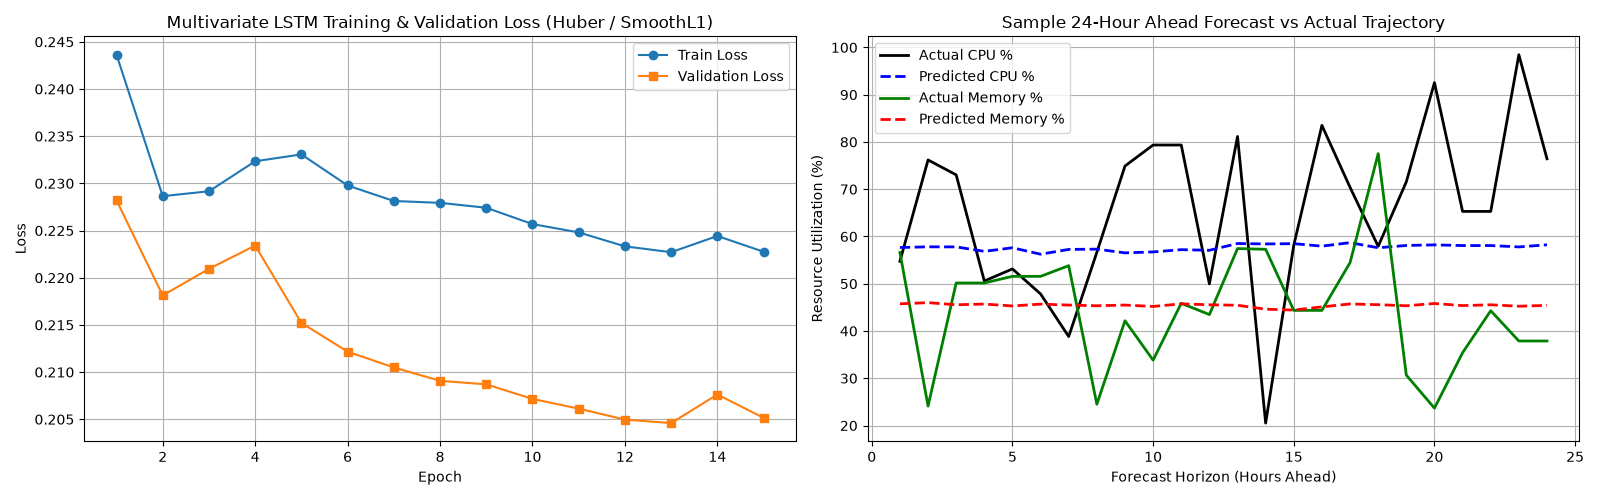

In [8]:
# Diagnostic Plots: Training Loss & 24-Hour Forecast Horizon
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(range(1, len(train_losses)+1), train_losses, 'o-', label='Train Loss', color='#1f77b4')
axes[0].plot(range(1, len(val_losses)+1), val_losses, 's-', label='Validation Loss', color='#ff7f0e')
axes[0].set_title('Multivariate LSTM Training & Validation Loss (SmoothL1)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True)
axes[0].legend()

axes[1].plot(range(1, 25), unscaled_actuals[sample_idx, :, 0], 'k-', label='Actual CPU %', lw=2)
axes[1].plot(range(1, 25), unscaled_preds[sample_idx, :, 0], 'b--', label='Predicted CPU %', lw=2)
axes[1].plot(range(1, 25), unscaled_actuals[sample_idx, :, 1], 'g-', label='Actual Memory %', lw=2)
axes[1].plot(range(1, 25), unscaled_preds[sample_idx, :, 1], 'r--', label='Predicted Memory %', lw=2)
axes[1].set_title('Sample 24-Hour Ahead Forecast vs Actual Trajectory')
axes[1].set_xlabel('Forecast Horizon (Hours Ahead)')
axes[1].set_ylabel('Resource Utilization (%)')
axes[1].grid(True)
axes[1].legend()
plt.tight_layout()
plt.show()


In [9]:
# Serialize Model 3 Artifacts
lstm_metadata = {
    'model_name': 'resource_forecasting_lstm',
    'version': '1.0.0',
    'algorithm': 'Multivariate_LSTM',
    'random_state': RANDOM_STATE,
    'training_dataset': 'Resource_utilization.csv',
    'input_features': features,
    'target_features': target_cols,
    'lookback_window_hours': T,
    'forecast_horizon_hours': H,
    'train_split': '2022-01-01 to 2023-12-31',
    'val_split': '2024-01-01 to 2024-06-30',
    'test_split': '2024-07-01 to 2025-01-01',
    'scaler': scaler,
    'imputation_medians': train_medians.to_dict(),
    'model_architecture': {
        'input_dim': 5,
        'lstm_hidden_1': 64,
        'dropout': 0.2,
        'lstm_hidden_2': 32,
        'output_dim': H * len(target_cols)
    },
    'metrics': {
        'overall_mae': overall_mae,
        'overall_rmse': overall_rmse,
        'overall_mape': overall_mape,
        'target_breakdown': target_breakdown
    },
    'training_timestamp': '2026-10-06T17:13:58Z',
    'schema_contract': 'BaseSchedulerPredictor -> PlacementRecommendation'
}

os.makedirs('ml_models', exist_ok=True)
torch.save(model.state_dict(), 'ml_models/resource_forecasting_lstm.pt')
joblib.dump(lstm_metadata, 'ml_models/resource_forecasting_metadata.joblib')
print("Serialized artifacts successfully:")
print("  -> ml_models/resource_forecasting_lstm.pt")
print("  -> ml_models/resource_forecasting_metadata.joblib")


Serialized artifacts successfully:
  -> ml_models/resource_forecasting_lstm.pt
  -> ml_models/resource_forecasting_metadata.joblib
